<a href="https://colab.research.google.com/github/matikk0/anti-fraud_/blob/main/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

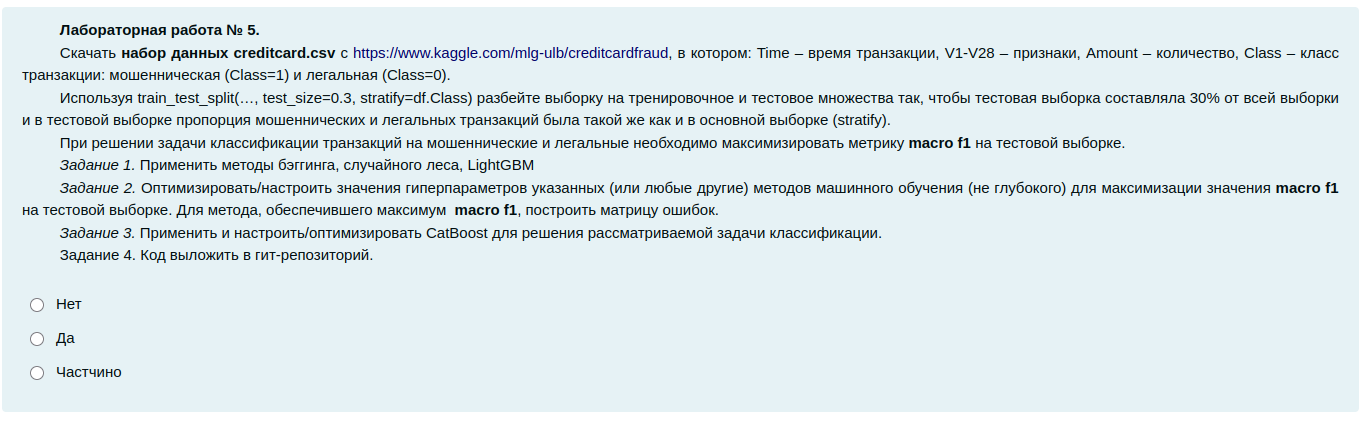

Загрузка данных с датасета, разбиение датасета на тренировочное и тестовое множества.

In [33]:
import kagglehub
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def stats_show(clf, y_true, y_pred):
  print(clf.best_estimator_)
  print(classification_report(y_true, y_pred))
  cm = confusion_matrix(y_true, y_pred, labels=clf.classes_)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels = clf.classes_)
  disp.plot()
  plt.show()

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
path += "/creditcard.csv"
transactions = pd.read_csv(path)
x = transactions.iloc[:, :30].to_numpy()
y = transactions['Class'].to_numpy()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, stratify = y)

Using Colab cache for faster access to the 'creditcardfraud' dataset.


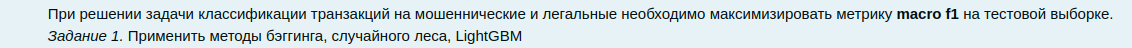

Бэггинг

BaggingClassifier(estimator=DecisionTreeClassifier(), max_samples=0.6,
                  n_estimators=15, n_jobs=-1)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.93      0.80      0.86       148

    accuracy                           1.00     85443
   macro avg       0.96      0.90      0.93     85443
weighted avg       1.00      1.00      1.00     85443



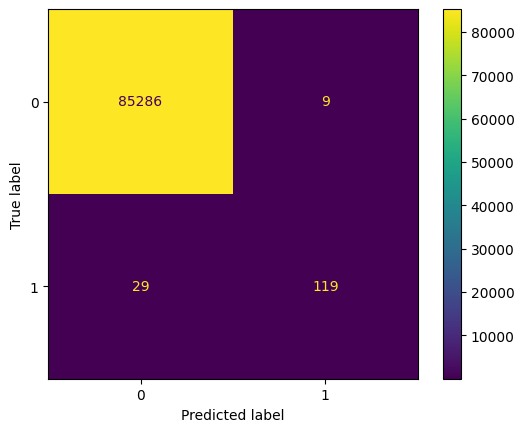

CPU times: user 8.3 s, sys: 1.83 s, total: 10.1 s
Wall time: 40min 10s


In [34]:
%%time
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier


params = {"n_estimators": [5, 10, 15], "max_samples": [0.6, 0.8]}
bagging = BaggingClassifier(DecisionTreeClassifier(),
                        n_jobs = -1)
clf = GridSearchCV(bagging, params, scoring="f1_macro", n_jobs=-1)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

stats_show(clf, y_test, y_pred)


Случайный лес


RandomForestClassifier(max_features='log2', n_estimators=30, n_jobs=-1,
                       random_state=42)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.95      0.78      0.86       148

    accuracy                           1.00     85443
   macro avg       0.98      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



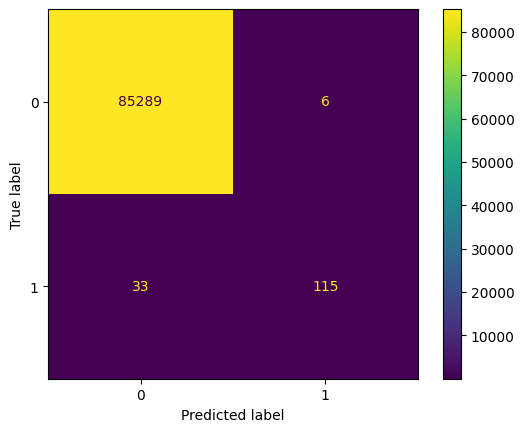

CPU times: user 2min 12s, sys: 1.91 s, total: 2min 13s
Wall time: 32min 1s


In [44]:
%%time
from sklearn.ensemble import RandomForestClassifier

params = {"n_estimators": [10, 20, 30], "class_weight": [None, "balanced"], "max_features": ["sqrt", "log2"]}
rfc = RandomForestClassifier(random_state=42, n_jobs=-1)
clf = GridSearchCV(rfc, params, scoring="f1_macro", n_jobs=-1)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

stats_show(clf, y_test, y_pred)

LightGBM

[LightGBM] [Info] Number of positive: 344, number of negative: 199020
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 199364, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001725 -> initscore=-6.360519
[LightGBM] [Info] Start training from score -6.360519


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBMClassifier(force_col_wise=True, learning_rate=0.01, n_estimators=300,
               n_jobs=-1, objective='binary')
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.96      0.72      0.82       148

    accuracy                           1.00     85443
   macro avg       0.98      0.86      0.91     85443
weighted avg       1.00      1.00      1.00     85443



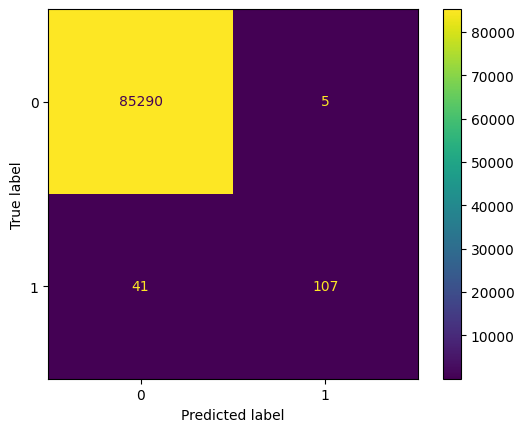

CPU times: user 28 s, sys: 809 ms, total: 28.8 s
Wall time: 12min 50s


In [45]:
%%time
import lightgbm as lgb

params = {"n_estimators": [75, 150, 300], "learning_rate": [0.01, 0.05, 0.1]}
lgbm = lgb.LGBMClassifier(objective = 'binary',
                         n_jobs = -1,
                          force_col_wise=True
)
clf = GridSearchCV(lgbm, params, scoring="f1_macro", n_jobs=-1)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

stats_show(clf, y_test, y_pred)

image.png

Catboost

In [46]:
!pip install catboost

[LightGBM] [Info] Number of positive: 344, number of negative: 199020
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 199364, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001725 -> initscore=-6.360519
[LightGBM] [Info] Start training from score -6.360519


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBMClassifier(force_col_wise=True, learning_rate=0.01, n_estimators=300,
               n_jobs=-1, objective='binary')
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.96      0.72      0.82       148

    accuracy                           1.00     85443
   macro avg       0.98      0.86      0.91     85443
weighted avg       1.00      1.00      1.00     85443



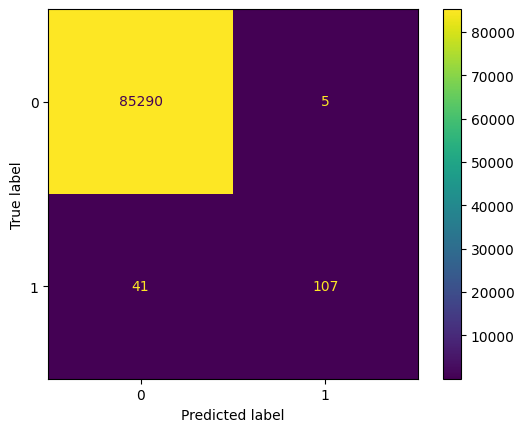

CPU times: user 27.1 s, sys: 746 ms, total: 27.8 s
Wall time: 12min 17s


In [47]:
%%time
from catboost import CatBoostClassifier

params = {"iterations": [250, 500, 750], "depth": [3, 6, 9], "learning_rate": [0.01, 0.05, 0.1]}
cb = CatBoostClassifier(loss_function = 'Logloss',
                         thread_count = -1)
GridSearchCV(cb, params, scoring="f1_macro", n_jobs=-1)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

stats_show(clf, y_test, y_pred)